# **Indian Union Budget 2025-2026 Analysis**




## 📖 1. Motive / Backstory
The **Union Budget of India** is the most highly anticipated economic event of the year. Delivered by the Hon'ble Finance Minister in the Parliament, this comprehensive speech doesn't just allocate funds—it sets the economic narrative, defines the government's priorities, and influences market sentiment for the entire fiscal year. 

However, a 30 to 40-page technical speech can be overwhelming to digest manually. While news channels provide summarized highlights, the raw, authentic tone and granular focus of the government often get lost in media interpretation. As data enthusiasts, we can leverage **Natural Language Processing (NLP)** to bypass the noise, directly analyze the authentic Parliamentary text, and let the data reveal the true focus of the budget.

---

## 🎯 2. Problem Statement
**Objective:** To systematically analyze the latest Union Budget Speech of India using Natural Language Processing (NLP) to extract underlying sentiments, dominant themes, and key sector priorities.

**Specific Goals of this Project:**
1. **Automated Extraction:** Fetch and parse the authentic budget speech document directly from the official India Budget portal.
2. **Text Processing (Cleaning):** Standardize the raw text by removing stop words, legal jargon, and punctuations to prepare a clean corpus.
3. **Thematic EDA:** Identify the most frequently emphasized words and sectors (e.g., Agriculture, Technology, Defense) to visualize the government's core focus areas using WordClouds and Frequency Plots.
4. **Sentiment & Tone Analysis:** Apply sentiment analysis to understand the emotional trajectory of the speech—identifying whether the overall tone is optimistic (growth-oriented), neutral (factual allocations), or cautious (focusing on inflation/deficits).

### **Library Importation**

In [1]:
!pip install python-dotenv groq google-generativeai google-genai


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
import requests
import os
import seaborn as sns
import nltk
import string
import ollama
import matplotlib.pyplot as plt
from google import genai
from google.genai import types
from docx import Document
from wordcloud import WordCloud
from textblob import TextBlob
from nltk.util import ngrams
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from collections import Counter
from scipy import stats
from dotenv import load_dotenv
from groq import Groq

import warnings
warnings.filterwarnings("ignore")


In [3]:
import nltk
import ssl


try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

nltk.download('punkt')
nltk.download('punkt_tab') 
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\AVIRAL\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [4]:
import pypdf

url = "https://www.indiabudget.gov.in/doc/bspeech/bs2025_26.pdf"
file_name = "Budget_Speech_2025-26.pdf"

print("Fetching 2025-26 Budget Speech...")
response = requests.get(url)

if response.status_code == 200:
    with open(file_name, "wb") as f:
        f.write(response.content)
    print(f"Data Successfully Downloaded as {file_name}")
else:
    print("Download failed!")

# Extract text page-by-page into paragraphs (li)
reader = pypdf.PdfReader(file_name)
li = []
for page in reader.pages:
    text = page.extract_text()
    if text:
        # Paragraphs split by newline
        paras = [p.strip() for p in text.split('\n') if len(p.strip()) > 30]
        li.extend(paras)

print(f"✅ Extraction Complete! Extracted {len(li)} paragraphs from 2025-26 Speech.")

Fetching 2025-26 Budget Speech...
Data Successfully Downloaded as Budget_Speech_2025-26.pdf
✅ Extraction Complete! Extracted 1227 paragraphs from 2025-26 Speech.


In [6]:
import pypdf

# PDF read karne ke liye
reader = pypdf.PdfReader(file_name)
li = []

for page in reader.pages:
    text = page.extract_text()
    if text:
        # Paragraphs ko break karke clean text nikaalna
        for p in text.split("\n"):
            p = p.strip()
            if len(p) > 25:  # chhote headers/page numbers filter karne ke liye
                li.append(p)

print(f"\n✅ Extraction Complete! The speech contains {len(li)} paragraphs.")
print("\n--- Initial Look at Data ---")
print(li[:2])


✅ Extraction Complete! The speech contains 1344 paragraphs.

--- Initial Look at Data ---
['Agriculture as the 1st engine 3', 'Investment as the 3rd engine 8']


In [7]:
stop_words = set(stopwords.words("english"))


custom_stop_words = stop_words.union({'crore', 'lakh', 'rupees', 'lakhs', 'crores', 'government', 'year', 'also', 'budget', 'per', 'cent', 'rs', 'percent', "rate"})


def clean_text(text):
    text = text.lower()
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = ''.join([i for i in text if not i.isdigit()])
    

    y = word_tokenize(text)

    cleaned_text = [w for w in y if w not in custom_stop_words and len(w) > 2]

    return " ".join(cleaned_text)


clean_paras = [clean_text(q) for q in li]

full_cleaned_Speech = " ".join(clean_paras)


print("Data Cleaning Completed")

print("Cleaned preview:", clean_paras[10][:100],"....")

Data Cleaning Completed
Cleaned preview: enhance spending power india rising middle class ....


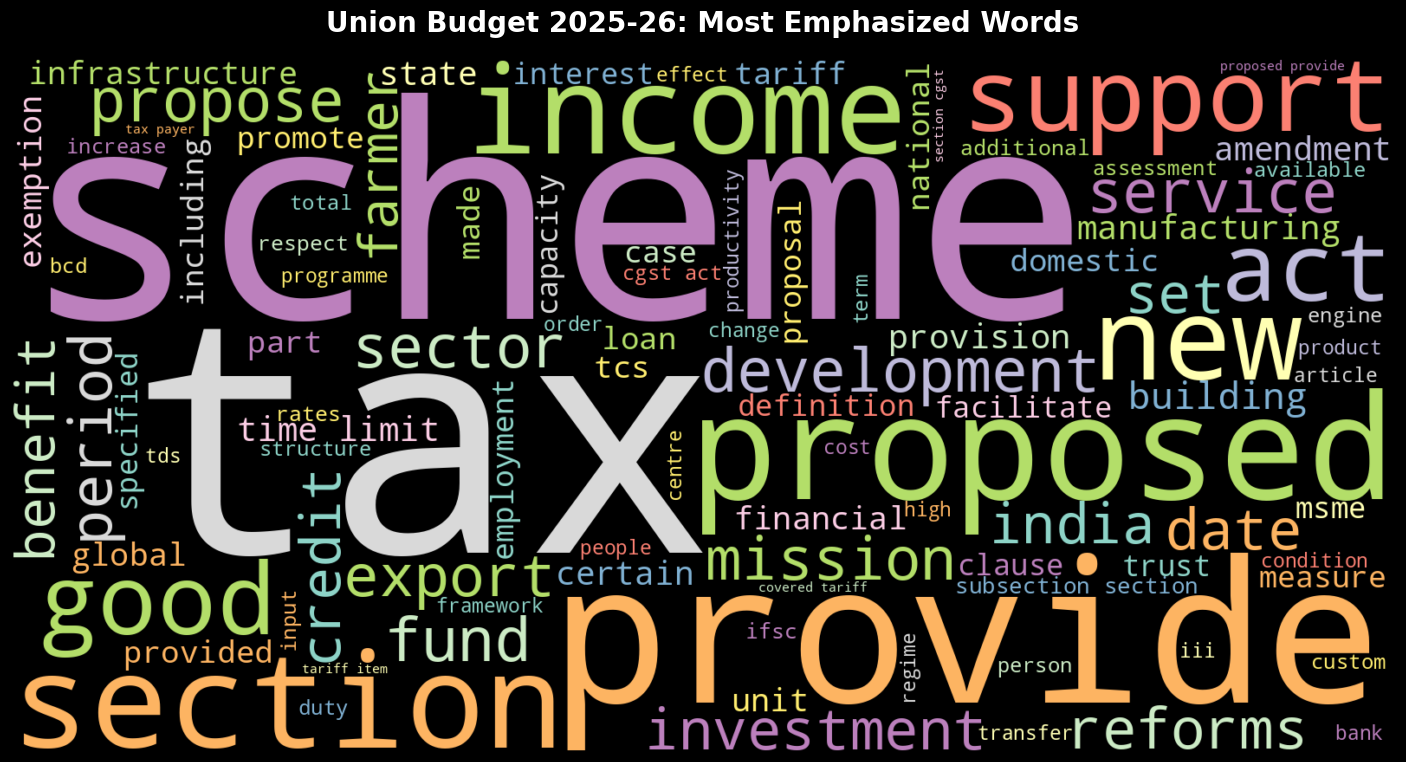

In [26]:
plt.figure(figsize=(18,9))
cloud = WordCloud(width=1600,height=800,background_color="black", colormap='Set3', max_words=101).generate(full_cleaned_Speech)
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.title("Union Budget 2025-26: Most Emphasized Words", fontsize=20, fontweight='bold', pad=20)
plt.show()

In [9]:
ls = full_cleaned_Speech.split()
cnt = Counter(ls)
top10 = cnt.most_common(10)

df = pd.DataFrame(top10, columns=['Word', 'Frequency'])
df

,Word,Frequency
0,tax,85
1,section,76
2,proposed,64
3,provide,53
4,tariff,48
5,scheme,44
6,act,42
7,new,39
8,propose,38
9,years,35


In [10]:
bigrams = ngrams(ls,2)
bigrams_freq = Counter(bigrams)


top10_bigrams = bigrams_freq.most_common(10)
bigrams_data = {"Bigrams" : [f"{q[0][0]} {q[0][1]}" for q in top10_bigrams],
                "Count" : [q[1] for q in top10_bigrams]}


df_bigrams = pd.DataFrame(bigrams_data)
df_bigrams

,Bigrams,Count
0,time limit,18
1,subsection section,13
2,cgst act,11
3,proposed provide,10
4,section cgst,10
5,covered tariff,10
6,tax payers,9
7,capital gains,9
8,middle class,8
9,next years,8


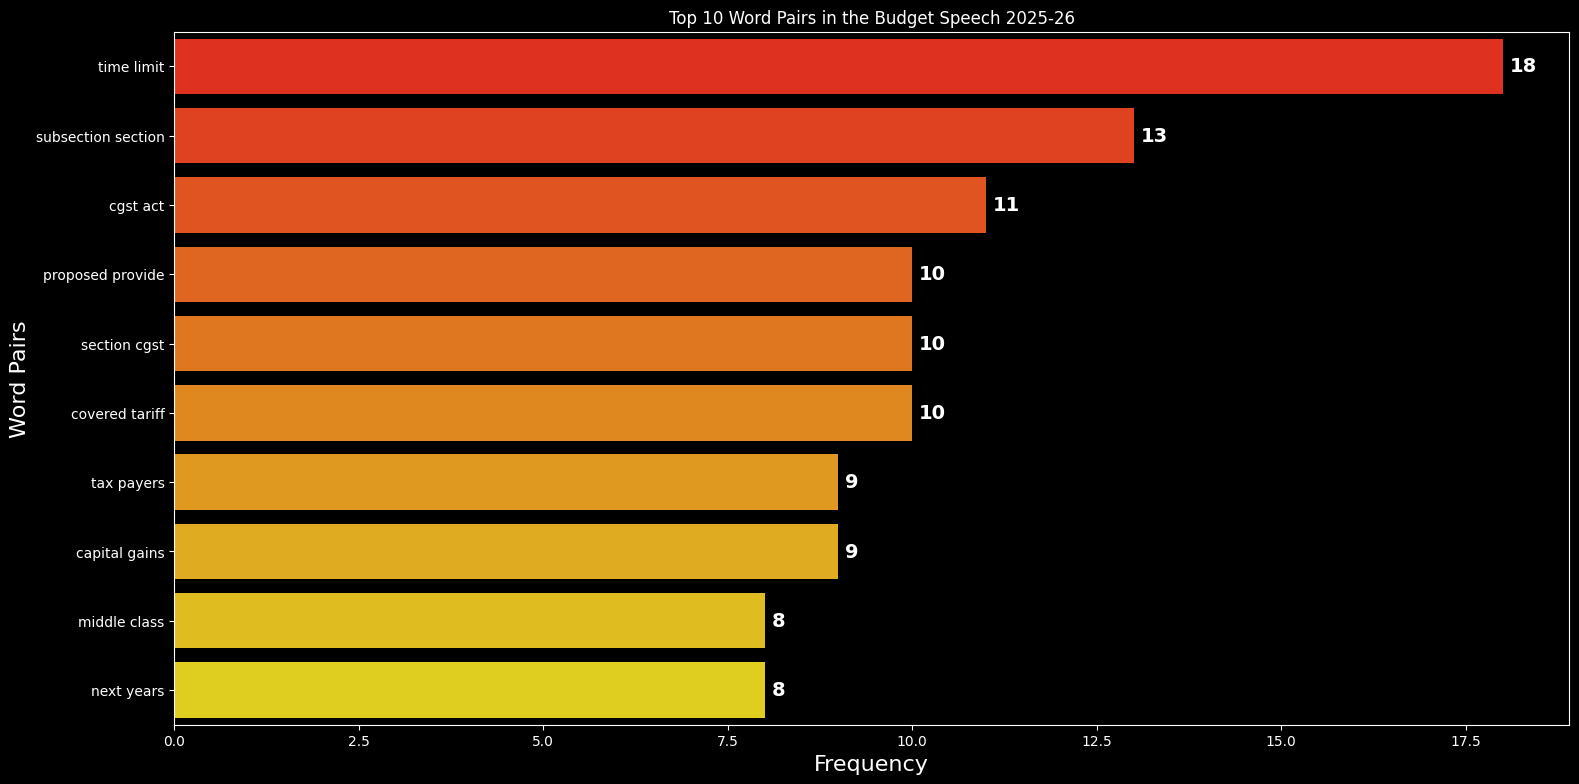

In [27]:
plt.style.use("dark_background") 

plt.figure(figsize=(18,9))
bar = sns.barplot(x="Count", y="Bigrams", data=df_bigrams, palette="autumn")

for i in bar.containers:

    bar.bar_label(i, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title('Top 10 Word Pairs in the Budget Speech 2025-26')
plt.xlabel("Frequency", fontsize=16)
plt.ylabel("Word Pairs", fontsize=16)
plt.show()

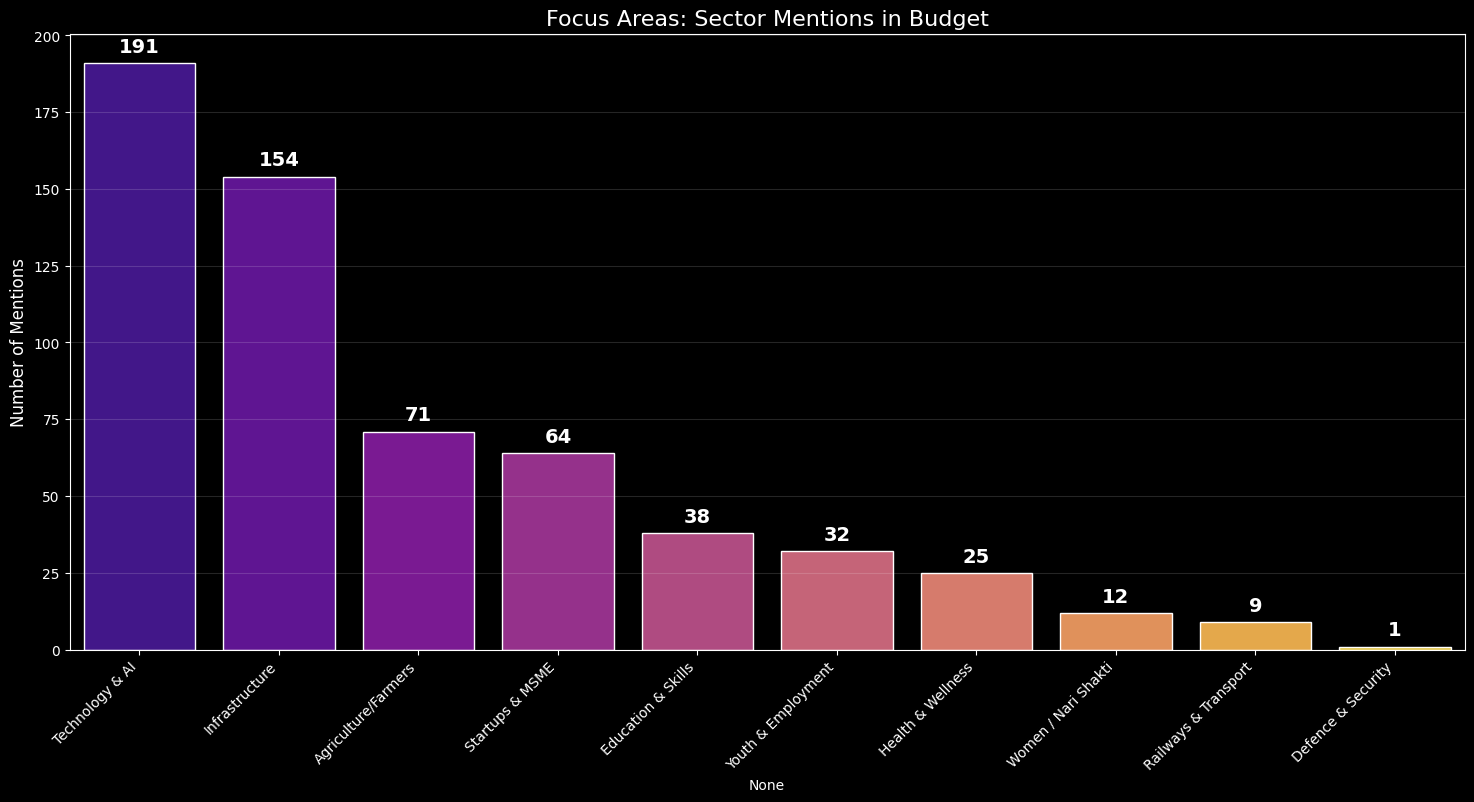

In [12]:
sec = {
    'Agriculture/Farmers': ['agriculture', 'farmer', 'farmers', 'kisan', 'crop', 'crops', 'rural', 'irrigation'],
    'Education & Skills': ['education', 'school', 'schools', 'college', 'university', 'students', 'learning', 'skill', 'skills'],
    'Health & Wellness': ['health', 'hospital', 'hospitals', 'medical', 'disease', 'vaccine', 'nutrition', 'ayushman'],
    'Railways & Transport': ['rail', 'railway', 'railways', 'train', 'trains', 'vande bharat', 'station', 'metro'],
    'Technology & AI': ['technology', 'digital', 'tech', 'ai', 'innovation', 'artificial intelligence', 'research'],
    'Defence & Security': ['defence', 'military', 'army', 'navy', 'airforce', 'armed forces', 'border'],
    'Women / Nari Shakti': ['women', 'woman', 'girl', 'girls', 'nari', 'shakti', 'mahila', 'matru'],
    'Youth & Employment': ['youth', 'young', 'employment', 'jobs', 'job', 'rozgar', 'career'],
    'Startups & MSME': ['startup', 'startups', 'msme', 'msmes', 'entrepreneur', 'entrepreneurship', 'business', 'businesses'],
    'Infrastructure': ['infrastructure', 'infra', 'roads', 'highway', 'highways', 'bridge', 'bridges', 'port', 'ports', 'aviation']
}

dict = {}

for sector_name, word_list in sec.items():
    total = 0
    for word in word_list:
        total += full_cleaned_Speech.count(word)
    dict[sector_name] = total

df_sec = pd.Series(dict).sort_values(ascending=False)

plt.figure(figsize=(18,8))
ax = sns.barplot(x=df_sec.index, y=df_sec.values, palette='plasma', edgecolor="white")

for container in ax.containers:
    ax.bar_label(container, padding=5, color='white', fontsize=14, fontweight='bold')

plt.title("Focus Areas: Sector Mentions in Budget", fontsize=16)
plt.ylabel("Number of Mentions", fontsize=12)
plt.xticks(rotation=45, ha='right') 
plt.grid(axis='y', alpha=0.15)
plt.style.use('dark_background')
plt.show()

In [13]:
lt = []

for i in clean_paras:
    if len(i) > 10:
        blob = TextBlob(i)

        lt.append(blob.sentiment.polarity)


df_sentiments = pd.DataFrame(lt, columns=['Polarity'])

avg_sentiment = df_sentiments["Polarity"].mean()




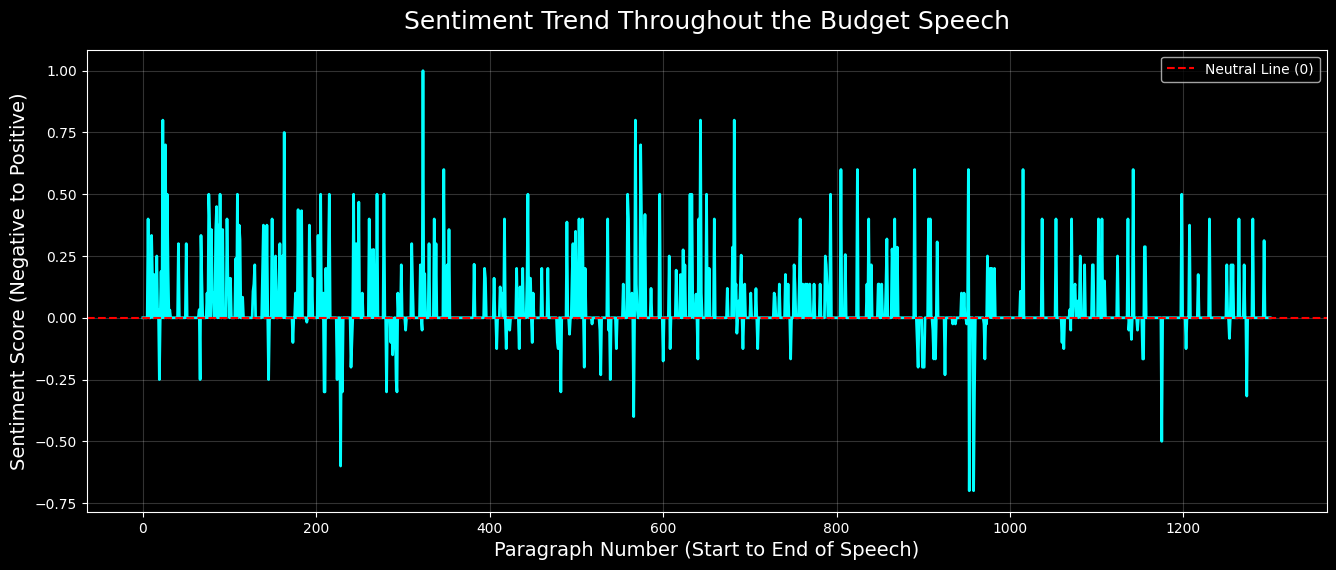

Sentiment Analysis Results
---------------------------------------------
Overall Tone: NEUTRAL (Factual/Balanced) | Score: 0.039


In [14]:
plt.figure(figsize=(16, 6))
plt.plot(df_sentiments['Polarity'], color='cyan', linewidth=2)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Neutral Line (0)')
plt.title("Sentiment Trend Throughout the Budget Speech", fontsize=18, pad=15)
plt.xlabel("Paragraph Number (Start to End of Speech)", fontsize=14)
plt.ylabel("Sentiment Score (Negative to Positive)", fontsize=14)
plt.legend()
plt.grid(alpha=0.2)
plt.style.use('dark_background')
plt.show()


print('Sentiment Analysis Results')
print("-"*45)
if avg_sentiment > 0.05:
        print(f"Overall Tone: POSITIVE (Optimistic & Growth-oriented) | Score: {avg_sentiment:.3f}")
elif avg_sentiment < -0.05:
    print(f"Overall Tone: CAUTIOUS / NEGATIVE | Score: {avg_sentiment:.3f}")
else:
    print(f"Overall Tone: NEUTRAL (Factual/Balanced) | Score: {avg_sentiment:.3f}")

In [15]:
desc_stats = df_sentiments[['Polarity']].describe().T.round(3)

desc_stats.columns = ['Total Paragraphs', 'Average (Mean)', 'Std Dev', 'Minimum', '25%', 'Median', '75%', 'Maximum']
desc_stats.index = ['Sentiment Tone']

desc_stats

,Total Paragraphs,Average (Mean),Std Dev,Minimum,25%,Median,75%,Maximum
Sentiment Tone,1301.0,0.039,0.142,-0.7,0.0,0.0,0.0,1.0


In [16]:
mp = len(df_sentiments)//2

hf1 = df_sentiments['Polarity'][:mp]
hf2 = df_sentiments['Polarity'][mp:]

print(f"First Half Average Sentiment: {hf1.mean():.3f}")
print(f"Second Half Average Sentiment: {hf2.mean():.3f}")


t_stat, pval = stats.ttest_ind(hf1, hf2)

print(f'''T-Test hypothesis 
Test Statistic Value = {t_stat:.4f}
P Value = {pval:.4f}''')


if pval < 0.05:

    print("\nConclusion: P-value is lower 0.05 threshold.")
    print("This refers to that we have a significant difference between tone of first half and second half")
else:
    print("\nConclusion: P-value is higher than 0.05 threshold.")
    print("This refers to that we don't have a significant difference between tone of first half and second half")



First Half Average Sentiment: 0.051
Second Half Average Sentiment: 0.028
T-Test hypothesis 
Test Statistic Value = 2.9134
P Value = 0.0036

Conclusion: P-value is lower 0.05 threshold.
This refers to that we have a significant difference between tone of first half and second half


In [17]:
from IPython.display import display, Markdown

def model_eval(model, text_data):

    print(f"{model.upper()} is analyzing the budget......")

    # Aapka exact same prompt, maine isme 1 word bhi change nahi kiya hai
    prompt =f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 

Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections:

### 1. Sector-Wise Allocations & Focus
Provide a detailed breakdown of what specific announcements, funds, or policies were made for the following 10 sectors. (If a sector was not significantly mentioned, state "Limited mentions"):
- Agriculture & Farmers
- Education & Skills
- Health & Wellness
- Railways & Transport
- Technology & AI
- Defence & Security
- Women / Nari Shakti
- Youth & Employment
- Startups & MSME
- Infrastructure

### 2. The 'Rupee Comes From' Analysis (Revenue)
Explain the government's revenue model. If the government earns 100 Rupees, break down exactly where this money is coming from (e.g., Corporate Tax, Income Tax, GST, Borrowings, Non-tax revenue, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Explain the government's expenditure model. If the government spends 100 Rupees, break down exactly where it is going (e.g., Interest Payments, Defence, Subsidies, State shares, Pensions, Central Sector Schemes, etc.). Provide the exact percentages or paise breakdown if mentioned in the text.

Format your response clearly using Markdown, bold text for key numbers, and bullet points. Do not hallucinate; use only the data present in the text provided below.

---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        response = ollama.chat(model=model, messages=[{'role' : "user", "content" :prompt}])
        print(f'\n {model.upper()} Budget Analysis')
        print("=" * 60)
        
        # YAHAN CHANGE KIYA HAI: print() hata diya, aur display(Markdown()) laga diya
        # Issey Output scrollable nahi aayega, balki professional formatted aayega
        display(Markdown(response['message']['content']))
        
        print("=" * 60 + "\n")

    except Exception as e:
        print("ERROR with Ollama Models therefore Kindly Check Again..............")

In [18]:
budget_doc = " ".join(li)
model_eval('phi3', budget_doc )

PHI3 is analyzing the budget......

 PHI3 Budget Analysis



The Budget proposes several amendments to the Income-tax Act, 1961, with a special focus on tax relief for the middle class under the new tax regime and rationalization of the tax deducted at source (TDS) and tax collected at source (TCS) for easing compliance difficulties. The amendments also aim to simplify the tax regime for various entities, including charitable trusts, investment funds, and startup businesses. The budget proposals also seek to extend various sunset dates, align definitions, and provide clarity on various tax-related issues. Here are the key amendments and rationalizations proposed in the budget:

1. Personal Income-tax reforms:

- Substantial relief is proposed under the new tax regime for the middle class, with no tax payable on income up to ` 12,00,000 due to a rebate. Marginal relief is also applicable for income marginally higher than ` 12,00,000.
- Personal income-tax rates are proposed to be rationalized, with 5%, 10%, 15%, and 20% tax rates proposed for income slabs up to ` 8,00,000, ` 16,00,000, and above ` 24,00,000 respectively. Income above ` 24,00,000 will be taxed at 30%.

2. Tax deducted at source (TDS) and tax collected at source (TCS):

- TDS and TCS rates for specific sections are proposed to be rationalized. Thresholds for TDS and TCS requirements in certain sections are also proposed to be increased.
- TDS/TCS on timber or any other tendu leaves obtained under specific sections are proposed to be increased.
- TDS/TCS on timber obtained by any mode other than under a forest lease is proposed to be rationalized.
- TDS/TCS on education financed by loan from a financial institution is proposed to be increased.
- TDS/TCS on sale of specified goods of value is proposed to be omitted.
- A prescribed reporting entity is proposed to furnish information about transactions in crypto-assets.
- Annual value of the self-occupied property is proposed to be nil for the owner who occupies the property for his own residence or cannot occupy it.
- Obligation to furnish information in respect of crypto-assets is proposed.
- Time-limit for filing the updated return is proposed to be extended from 24 to 48 months.

3. Reducing compliance burden:

- Time-limit for passing an order on immunity from penalty and prosecution is proposed to be extended from three months to six months.
- Time-limit for imposition of penalties is proposed to be rationalized.
- Time-limit for retention of seized books of account or other documents is proposed to be one month from the end of the quarter.
- Time-limit for completion of block assessment is proposed to be twelve months.
- Time-limit for calculation of capital gains on redemption of Unit Linked Insurance Policy is proposed to be extended to three years.
- Time-limit for making investment by Sovereign Wealth Funds is proposed to be extended to three years.
- Time-limit for exemptions, deductions, and relocation is proposed to be extended to March 31, 2030.
- Time-limit for assessment and reassessment orders to be extended to March 31, 2030.

4. Employment and Investment:

- Exemption from withdrawals from National Savings Scheme (NSS) is proposed for withdrawals made after August 29, 2024.
- Increase in the limits on the income of employees is proposed.
- Exemption for the Specified Undertaking of Unit Trust of India is proposed to be extended to March 31, 2030.
- Non-applicability of Section 271AAB of the Act is proposed.
- Certain penalties are proposed to be imposed by the Assessing Officer.

5. Miscellaneous amendments:

- Exemption for income accrued or arising to a non-resident from transfer of non-deliverable forward contracts with a Foreign Portfolio Investor is proposed.
- The exemption in section 10(4H) for capital gains on transfer of equity shares of a ship leasing domestic company is proposed to be extended to dividends.
- The exemption in section 10(34B) for dividend paid by a ship leasing company in IFSC is proposed to be extended to a unit of IFSC.
- Advance or loan between two group entities, where one is set up in IFSC for treasury activities, is proposed to be excluded from TDS/TCS.
- Deduction u/s 80CCD for contributions made to NPS Vatsalya is proposed to be extended to NPS Vatsalya accounts.

6. Block assessment for search and requisition cases:

- Amendments are proposed to define "virtual digital asset" and add it to the definition of undisclosed income of the block period.
- Time-limit for completion of block assessment is proposed to be twelve months.

7. Other amendments:

- Exemption for income from life insurance policy issued by an IFSC insurance intermediary office is proposed without the condition on maximum premium amount.
- Period of sunset dates related to IFSC units is proposed to be extended to March 31, 2030.
- Time-limit for making investment by Sovereign Wealth Funds is proposed to be extended to March 31, 2030.
- Parity in rates of long term capital gain on transfer of securities by non-residents and residents is proposed.
- Harmonization of significant economic presence applicability with transactions or activities confined to the purchase of goods in India is proposed.

8. Ease of doing business:

- Time-limit for eligibility for startups under Section 80-IAC is proposed to be extended to five years.
- Simplification of tax provisions for charitable trusts/institutions is proposed.
- Parity in rates of long term capital gain on transfer of securities for foreign institutional investors is proposed.
- Extension of the scheme of presumptive taxation for non-residents providing services for establishing or operating electronics manufacturing facilities is proposed.
- Deduction u/s 80CCD for contributions to the NPS Vatsalya is proposed.
- Simplification of tax provisions for investment funds managed by fund manager based in IFSC is proposed.
- The exemption for transfer of a share or unit in an original fund for relocation is proposed.
- Time-limit for passing orders under section 115VP is proposed to be three months.
- Time-limit for imposition of penalties is proposed to be rationalized.
- Time-limit for retention of seized books of account or other documents is proposed to be one month.
- Time-limit for completion of block assessment is proposed to be twelve months.

9. Clarification and rationalization:

- Clarification regarding commencement date and the end date of the period stayed by the court is proposed.
- Time-limit for calculating time limit to impose penalties is proposed to be rationalized.
- Time-limit for retention of seized books of account or other documents is proposed to be one month.
- Time-limit for calculation of capital gains on redemption of a Unit Linked Insurance Policy is proposed to be extended to three years.
- Time-limit for making investment by Sovereign Wealth Funds is proposed to be extended to three years.
- Time-limit for exemptions, deductions, and relocation is proposed to be extended to March 31, 2030.
- Time-limit for assessment and reassessment orders is proposed to be extended to March 31, 2030.

10. Amendments:

- Exemption from prosecution for delayed payment of TCS is proposed.
- Clarification regarding commencement date and the end date of the period stayed by the court is proposed.
- Time-limit for imposing penalties is proposed to be rationalized.
- Time-limit for retention of seized books of account or other documents is proposed to be one month.

In summary, the budget proposes a mix of tax relief measures, rationalization of TDS/TCS, simplification of tax provisions, and changes aimed at reducing compliance burden for taxpayers and entities, while also introducing new measures related to crypto-assets and block assessment.

In [19]:
budget_doc = " ".join(li)
model_eval('llama3.1', budget_doc )

LLAMA3.1 is analyzing the budget......

 LLAMA3.1 Budget Analysis


The text appears to be a summary of changes to the Indian budget and taxation laws as announced in the Union Budget of 2023. Here are the key points summarized:

**Customs Tariff**

* 13 changes to the Customs Tariff, including:
	+ Reduction in tariffs for certain goods, such as:
		- Synthetic flavoring essences and mixtures of odoriferous substances
		- Sorbitol
		- Articles of jewelry and parts thereof
		- Solar modules
	+ Increase in tariffs for certain goods, such as:
		- Motor vehicles for passenger and goods
		- Seats and parts thereof
		- Other furniture and parts thereof
* Increase in duration for export of handicrafts manufactured from duty-free inputs
* Removal of Customs (Import of Goods at Concessional rate of duty or For Specific End Use) Rules 2022 (IGCR) condition for import of seeds for use in manufacture of Lab Grown Diamonds
* Extension of time limit for export of foreign origin goods imported for repairs
* Amendment of Customs (Import of Goods at Concessional Rate of Duty or For Specified End Use) Rules, 2022

**Direct Taxes**

* Personal Income-tax reforms with special focus on middle class:
	+ Substantial relief is proposed under the new tax regime with new slabs
	+ Resident individual with total income up to ₹ 7,00,000 do not pay any tax due to rebate under the new tax regime
	+ Increase in rebate for resident individual under the new regime so that they do not pay tax if their total income is up to ₹ 12,00,000
* Rationalization of TDS/TCS for easing difficulties:
	+ Reduction in multiplicity of rates and compliance burden
	+ Increase in certain thresholds for requirement to deduct tax at source or collect tax at source
* Employment and Investment:
	+ Extension of sunset dates related to IFSC units for exemptions, deductions and relocation
	+ Exemption from withdrawals from National Savings Scheme (NSS)
	+ Increase in the limits on the income of the employees for the purpose of
	+ Extension of exemption to Specified Undertaking of Unit Trust of India
	+ Non-applicability of Section 271AAB of the Act
	+ Certain penalties to be imposed by the Assessing Officer
	+ Removing date restrictions on framing the schemes in certain cases
	+ Extending the processing period of Application seeking immunity from penalty and prosecution
	+ Increasing time limit available to pass order under section 115VP
	+ Excluding the period such as court stay etc. for calculating time limit to
	+ Time limit to impose penalties rationalized
	+ Clarification regarding commencement date and the end date of the period stayed by the Court
	+ Time limit for retention of seized books of account or other documents
	+ Rationalisation of provisions related to carry forward of losses in case
	+ Amendments proposed in provisions of Block assessment for search and requisition cases under Chapter XIV-B

In [20]:
budget_doc = " ".join(li)
model_eval('qwen2', budget_doc )

QWEN2 is analyzing the budget......

 QWEN2 Budget Analysis


The Union Budget 2023-24 presented by the Finance Minister Nirmala Sitharaman on February 1, 2023, included several proposals that affect various sectors of the economy. Here are some of the key highlights:

1. **Furniture and Parts:**
   - Mattresses, mattress supports, articles of bedding, and furnishing.
   - Luminaries and light fittings including searchlights and spotlights.
   - Electronic toys parts.
   - Laboratory chemicals.

2. **Duty Exemptions:**
   - Export of handicrafts by bonafide exporters is increased from 6 months to 1 year, extendable by 3 months.
   - Removal of Customs (Import of Goods at Concessional rate of duty or For Specific End Use) Rules 2022 condition for seeds used in lab-grown diamond manufacturing.

3. **Personal Income Tax Reforms:**
   - Introduction of new tax slabs with significant relief:
     - Up to Rs. 4 lakh: 5%.
     - Rs. 4 lakh to Rs. 8 lakh: 10%.
     - Rs. 8 lakh to Rs. 16 lakh: 15%.
     - Rs. 16 lakh to Rs. 20 lakh: 20%.
     - Rs. 20 lakh to Rs. 24 lakh: 25%.
     - Above Rs. 24 lakh: 30%.
   - Rebate for residents up to Rs. 12 lakh.

4. **TDS/TCS Rationalization:**
   - Reduction of certain TDS/TCS rates and introduction of higher thresholds for deduction requirements.

5. **Ease of Doing Business:**
   - Extension of time for startups under Section 80-IAC.
   - Parity in taxation for non-residents on long-term capital gains from securities.
   - Simplification of tax provisions for charitable trusts.

6. **Exemptions and Incentives:**
   - Exemption of life insurance policy proceeds from IFSC offices.
   - Extension of exemptions for IFSC units related to capital gains, dividends, loans to group entities, investment funds, and non-residents.
   - Extension of the sunset date for IFSC units to March 31, 2030.

7. **Miscellaneous Amendments:**
   - Exemption from withdrawals from the National Savings Scheme after August 29, 2024.
   - Amendment of the National Pension Scheme (NPS) Vatsalya account tax benefits.
   - Exemption for NPS (Vatsalya) contributions.

8. **Other Provisions:**
   - Rationalization of rules for TCS, penalties, and processing periods for applications.
   - Amendments to tax slabs for personal income tax.

These proposals aim to streamline regulations, reduce compliance burden, and encourage investment and growth across various sectors while providing targeted relief to individuals and businesses.

In [21]:
import os
from dotenv import load_dotenv

# .env file ko read karna
load_dotenv()

GROQ_KEY = os.getenv("GROQ_API_KEY")
GEMINI_KEY = os.getenv("GEMINI_API_KEY")


if GROQ_KEY:
    print(f" GROQ Key Loaded Successfully! (Starts with: {GROQ_KEY[:4]}...)")
else:
    print(" GROQ Key Not Found!")

# Check Gemini Key
if GEMINI_KEY:
    print(f"GEMINI Key Loaded Successfully! (Starts with: {GEMINI_KEY[:4]}...)")
else:
    print("GEMINI Key Not Found!")

 GROQ Key Not Found!
GEMINI Key Not Found!


In [ ]:
def gemini_model_eval(text_data):
    print("⏳ GEMINI is analyzing the budget......\n")

    prompt = f"""You are a highly skilled Economic Analyst and Data Scientist analyzing the Indian Union Budget Speech. 
Based strictly on the provided budget speech text, I need a comprehensive, structured, and highly detailed analysis broken down into the following three specific sections. 

CRITICAL RULE: You MUST output all three sections as Markdown Tables. 
CRITICAL INSTRUCTION: Keep the analysis EXTREMELY CONCISE. Provide a MAXIMUM of 3 very short bullet points per sector. Do not repeat any points.

### 1. Sector-Wise Allocations & Focus
Create a Markdown Table with two columns: 'Sector' and 'Key Announcements/Allocations'. 
Analyze these 10 sectors: Agriculture & Farmers, Education & Skills, Health & Wellness, Railways & Transport, Technology & AI, Defence & Security, Women / Nari Shakti, Youth & Employment, Startups & MSME, Infrastructure. (If not mentioned, write 'Limited mentions').

### 2. The 'Rupee Comes From' Analysis (Revenue)
Create a Markdown Table with two columns: 'Revenue Source' and 'Details/Percentage'. (If exact numbers aren't there, summarize major tax sources).

### 3. The 'Rupee Goes To' Analysis (Expenditure)
Create a Markdown Table with two columns: 'Expenditure Area' and 'Details/Percentage'. (If exact numbers aren't there, summarize major spending areas).

Do not hallucinate; use only the data present in the text provided below.
---
BUDGET SPEECH TEXT:
{text_data}
"""
    
    try:
        client = genai.Client(api_key="")
        
        response = client.models.generate_content(
            model='gemini-3.5-flash',
            contents=prompt,
            config=types.GenerateContentConfig(
                temperature=0.2,
            )
        )
            
        print('🌟 GEMINI Budget Analysis 🌟')
        print("=" * 60)
        display(Markdown(response.text))
        print("=" * 60 + "\n")
        
    except Exception as e:
        print(f"❌ ERROR with GEMINI API: {e}")

In [25]:
gemini_model_eval(budget_doc)

⏳ GEMINI is analyzing the budget......

🌟 GEMINI Budget Analysis 🌟


### 1. Sector-Wise Allocations & Focus

| Sector | Key Announcements/Allocations |
| :--- | :--- |
| **Agriculture & Farmers** | • Launched 'PM Dhan-Dhaanya Krishi Yojana' covering 100 low-productivity districts.<br>• Enhanced Kisan Credit Card (KCC) loan limit under Modified Interest Subvention from ₹3 lakh to ₹5 lakh.<br>• Announced 6-year Mission for Aatmanirbharta in Pulses (Tur, Urad, Masoor) and Mission for Cotton Productivity. |
| **Education & Skills** | • Establishing 50,000 Atal Tinkering Labs and 5 National Centres of Excellence for Skilling.<br>• Added capacity for 6,500 students across 5 IITs; set up ₹500 crore Centre of Excellence in AI for Education.<br>• Launched Bharatiya Bhasha Pustak Scheme for digital Indian language textbooks. |
| **Health & Wellness** | • Adding 10,000 medical seats next year towards a 5-year target of 75,000 seats.<br>• Setting up Day Care Cancer Centres in all district hospitals (200 centres in Year 1).<br>• Fully exempted Basic Customs Duty on 36 lifesaving drugs; enhanced Poshan 2.0 nutritional support norms. |
| **Railways & Transport** | • Launched modified UDAN scheme to cover 120 new regional destinations for 4 crore passengers.<br>• Created ₹25,000 crore Maritime Development Fund and revamped Shipbuilding Financial Assistance Policy.<br>• Extended repair export time-limit to 1 year for domestic MROs handling railway goods. |
| **Technology & AI** | • Allocated ₹500 crore for a Centre of Excellence in Artificial Intelligence for education.<br>• Announced National Geospatial Mission for land record modernization and urban planning.<br>• Created 'BharatTradeNet' DPI unified platform for digital trade documentation and financing. |
| **Defence & Security** | • Limited mentions |
| **Women / Nari Shakti** | • Target of 70% women in economic activities; launched entrepreneurship scheme for 5 lakh women, SC, and STs (loans up to ₹2 crore).<br>• Enhanced nutritional support for 1 crore pregnant/lactating women under Poshan 2.0.<br>• Focused skilling and employment measures for rural women under the Rural Prosperity programme. |
| **Youth & Employment** | • Registered 1 crore online platform/gig workers on e-Shram portal with PM Jan Arogya Yojana coverage.<br>• Introduced Focus Product Scheme in Footwear & Leather targeted to generate 22 lakh jobs.<br>• Offering 10,000 PM Research Fellowships for advanced technology research in IITs and IISc. |
| **Startups & MSME** | • Enhanced MSME classification limits (2.5x investment, 2x turnover) and raised credit guarantee limits to ₹10 cr (MSEs) & ₹20 cr (Startups).<br>• Set up new Fund of Funds with ₹10,000 crore contribution; extended startup tax incorporation date to 2030.<br>• Introduced Udyam-linked Credit Cards with ₹5 lakh limit for 10 lakh micro enterprises. |
| **Infrastructure** | • Outlaid ₹1.5 lakh crore in 50-year interest-free loans to states for capital expenditure.<br>• Launched Asset Monetization Plan 2025-30 (target ₹10 lakh crore) and ₹1 lakh crore Urban Challenge Fund.<br>• Allocated ₹20,000 crore for Nuclear Energy Mission (Small Modular Reactors) targeting 100 GW nuclear capacity by 2047. |

---

### 2. The 'Rupee Comes From' Analysis (Revenue)

| Revenue Source | Details/Percentage |
| :--- | :--- |
| **Total Receipts (Excluding Borrowings)** | • Estimated at ₹34.96 lakh crore for FY 2025-26 (Revised Estimate FY 2024-25: ₹31.47 lakh crore). |
| **Net Tax Receipts** | • Estimated at ₹28.37 lakh crore for FY 2025-26 (Revised Estimate FY 2024-25: ₹25.57 lakh crore). |
| **Market Borrowings (Deficit Financing)** | • Gross market borrowings estimated at ₹14.82 lakh crore.<br>• Net market borrowings from dated securities estimated at ₹11.54 lakh crore. |
| **Other Financing Sources** | • Small savings and miscellaneous capital receipts finance the balance fiscal deficit target (estimated at 4.4% of GDP for 2025-26). |
| **Tax Revenue Structure & Relief Impact** | • Direct Taxes: Income tax exemptions up to ₹12 lakh under new regime; revenue forgone estimated at ₹1 lakh crore.<br>• Indirect Taxes: Rationalized customs structure to 8 standard rates; revenue forgone estimated at ₹2,600 crore. |

---

### 3. The 'Rupee Goes To' Analysis (Expenditure)

| Expenditure Area | Details/Percentage |
| :--- | :--- |
| **Total Budget Expenditure** | • Estimated at ₹50.65 lakh crore for FY 2025-26 (Revised Estimate FY 2024-25: ₹47.16 lakh crore). |
| **Capital Expenditure (CapEx)** | • Total CapEx for FY 2024-25 RE stands at ~₹10.18 lakh crore.<br>• Includes ₹1.5 lakh crore allocated as 50-year interest-free loans to states for local CapEx. |
| **Urban Development & Infrastructure Funds** | • ₹10,000 crore initial allocation for FY 2025-26 under the ₹1 lakh crore Urban Challenge Fund.<br>• ₹15,000 crore corpus allocated for SWAMIH Fund 2 for affordable housing projects. |
| **Research, Innovation & Clean Energy** | • ₹20,000 crore allocated for private sector-driven R&D and Innovation.<br>• ₹20,000 crore outlay for the Nuclear Energy Mission for Small Modular Reactors (SMRs). |
| **Sectoral Missions & Financial Intermediaries** | • ₹10,000 crore government contribution to the new Fund of Funds for Startups.<br>• Up to 49% government contribution in the new ₹25,000 crore Maritime Development Fund. |